# Day 3-01｜2 枚の画像のどの矩形が同じ選手を表すか：IoU による対応付け

[Colab で開く](https://colab.research.google.com/github/henry753951/basketball-hackathon-course/blob/main/day3/d3_01_tracking_concept_iou_association_ja.ipynb)

[English](d3_01_tracking_concept_iou_association_en.ipynb) | [Japanese](d3_01_tracking_concept_iou_association_ja.ipynb) | [Traditional Chinese](d3_01_tracking_concept_iou_association.ipynb)


> Day 2 では各フレームで選手を検出したが、`Frame 15` の矩形が `Frame 16` のどの矩形と同じ人物かは分からない。  
> まず処理を追いやすい IoU の対応付けで追跡を理解し、次の単元で ByteTrack による長い動画の追跡へ進む。

## 学習目標

- 前後の画像の矩形に `A0, A1, ...`、`B0, B1, ...` と名前を付ける。
- 共通部分、和集合、IoU を順に計算し、全組み合わせの行列を作る。
- ヒートマップで、各 A 矩形とすべての B 矩形の関係を確認する。
- 全候補を対象にした貪欲法で一対一の対応を求め、画像に線を描く。

## 用語

- **対応付け（Association）**：異なるフレームの検出が同じ対象かどうかを判断すること。
- **IoU（Intersection over Union）**：二つの矩形の共通面積を和集合の面積で割った値。0 から 1 の範囲を取る。
- **貪欲法（Greedy）**：競合しない候補の中から、その時点で最もスコアの高い組を順に選ぶ方法。


## この単元の位置付け

- 隣接する 2 フレームだけを比較し、対応付けを理解する。ByteTrack 全体の再実装は行わない。
- CPU でも処理できる。YOLO の推論が遅い場合は `IMGSZ` を小さくする。
- 最終的な対応表だけでなく、画像、行列、対応線を合わせて確認する。


## 演習の流れ

1. 隣接する 2 フレームで検出を行い、選手の矩形だけを残す。
2. `A0...`、`B0...` と表示し、行列の行・列を実際の矩形に対応させる。
3. すべての `A_i` と `B_j` の IoU を計算し、ヒートマップを描く。
4. 全候補を IoU の高い順に並べ、重複のない一対一の対応を作る。
5. 両画像に対応線を描き、高速移動、遮蔽、矩形の揺れによる失敗を考える。


In [1]:
import os
os.environ["BASKETBALL_COURSE_LANGUAGE"] = "ja"

# リポジトリを探し、環境を準備して共通モジュールを読み込みます。
from pathlib import Path
import subprocess
import sys

DRIVE_MOUNTED = False
if "google.colab" in sys.modules:
    from google.colab import drive

    try:
        drive.mount("/content/drive")
        DRIVE_MOUNTED = True
    except NotImplementedError:
        print("この Colab ランタイムでは Drive をマウントできないため、ローカルの /content を使います。")

COURSE_ROOT_HINT = (
    Path("/content/drive/MyDrive/basketball_hackathon/course")
    if DRIVE_MOUNTED
    else next(
        (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
         if (p / "src" / "course_setup.py").exists()),
        Path("/content/basketball_hackathon/course"),
    )
)
if not (COURSE_ROOT_HINT / "src" / "course_setup.py").exists() and "google.colab" in sys.modules:
    COURSE_ROOT_HINT.parent.mkdir(parents=True, exist_ok=True)
    subprocess.run([
        "git", "clone", "--depth", "1", "https://github.com/henry753951/basketball-hackathon-course.git", str(COURSE_ROOT_HINT)
    ], check=True)
if str(COURSE_ROOT_HINT) not in sys.path:
    sys.path.insert(0, str(COURSE_ROOT_HINT))

from src.course_setup import bootstrap_course_repo  # noqa: E402

COURSE_ROOT = bootstrap_course_repo(COURSE_ROOT_HINT, mount_drive=False)


教材ルート： /Users/henry753951/Developer/sandbox/basketball-hackathon-course
素材フォルダ： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets
共通モジュール： /Users/henry753951/Developer/sandbox/basketball-hackathon-course/src


## Step 1｜動画、モデル、隣接フレームを選ぶ

`FRAME_B = FRAME_A + 1` は連続するフレームを比較する設定である。時間差が小さいほど、同じ選手の矩形は通常よく重なり、IoU による対応付けがしやすい。


In [2]:
# データの場所と実験パラメータを設定します。
import matplotlib.pyplot as plt
from matplotlib.patches import ConnectionPatch, Rectangle
import numpy as np
import pandas as pd

from src.yolo_utils import (
    PLAYER_CLASS_NAMES,
    detector_model_path,
    first_reference_video,
    read_video_frame,
    run_detector_on_image,
)

VIDEO_PATH = first_reference_video(COURSE_ROOT)
MODEL_PATH = detector_model_path(COURSE_ROOT)
FRAME_A = 15
FRAME_B = FRAME_A + 1  # 最初は連続するフレームだけを比較します。
CONF = 0.25            # この信頼度を下回る検出を除きます。
IMGSZ = 960            # 入力を小さくすると速くなりますが、小物体を見落としやすくなります。

print("video:", VIDEO_PATH)
print("model:", MODEL_PATH)
print("frames:", FRAME_A, "->", FRAME_B)


video: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/raw/reference_videos/boston-celtics-new-york-knicks-game-1-q1-01.54-01.48.mp4
model: /Users/henry753951/Developer/sandbox/basketball-hackathon-course/assets/models/detectors/yolo26n_basketball_player_best.pt
frames: 15 -> 16


## Step 2｜各検出矩形に番号を付ける

`A2` は選手の固定 ID ではなく、Frame A の 3 番目の矩形を表す。`B2` も Frame B の 3 番目である。フレームをまたぐ ID は、対応付けの後に初めて作られる。


In [3]:
# 2 枚を読み、検出を実行して player クラスだけを残します。
frame_a = read_video_frame(VIDEO_PATH, FRAME_A)
frame_b = read_video_frame(VIDEO_PATH, FRAME_B)

dets_a, _ = run_detector_on_image(
    MODEL_PATH, frame_a, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_A
)
dets_b, _ = run_detector_on_image(
    MODEL_PATH, frame_b, conf=CONF, imgsz=IMGSZ, frame_index=FRAME_B
)

players_a = [det for det in dets_a if det.class_name in PLAYER_CLASS_NAMES]
players_b = [det for det in dets_b if det.class_name in PLAYER_CLASS_NAMES]

print(f"Frame A：選手の矩形 {len(players_a)} 個")
print(f"Frame B：選手の矩形 {len(players_b)} 個")


Frame A：選手の矩形 10 個
Frame B：選手の矩形 9 個


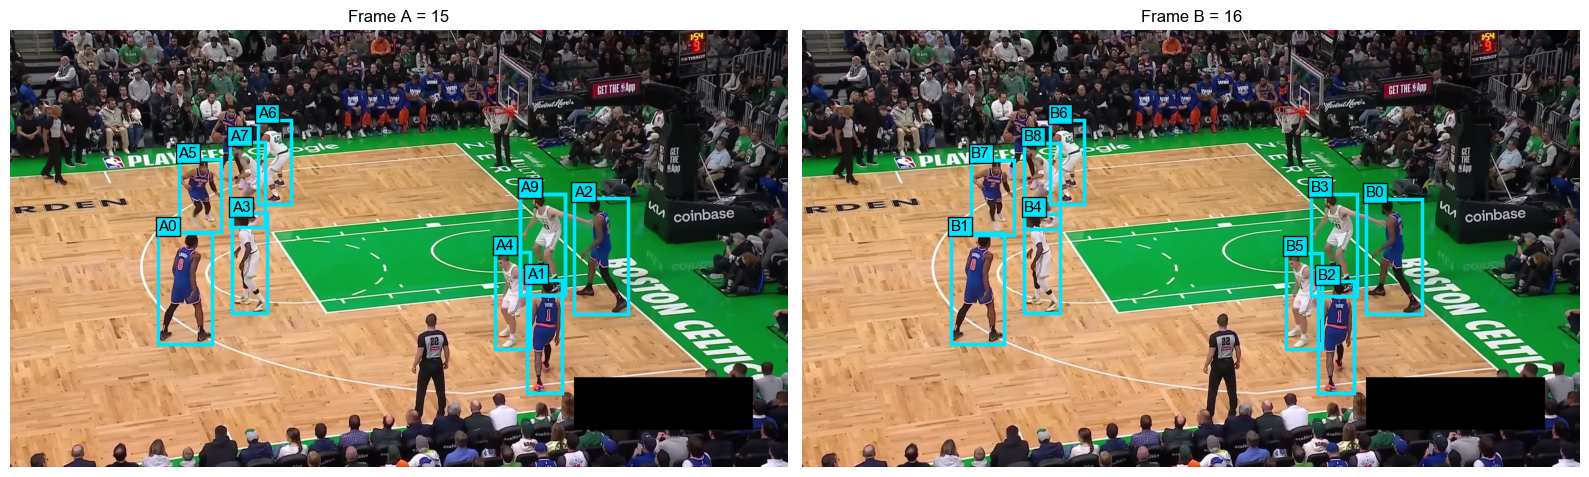

In [4]:
# 行列の A0／B0 ラベルを実際の矩形に描きます。
def draw_indexed_boxes(ax, image, detections, prefix, title):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")
    for index, det in enumerate(detections):
        x1, y1, x2, y2 = det.bbox_xyxy
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1,
                               fill=False, edgecolor="#00E5FF", linewidth=2.5))
        ax.text(x1, max(0, y1 - 6), f"{prefix}{index}", color="black",
                fontsize=11, weight="bold",
                bbox={"facecolor": "#00E5FF", "alpha": 0.9, "pad": 2})

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
draw_indexed_boxes(axes[0], frame_a, players_a, "A", f"Frame A = {FRAME_A}")
draw_indexed_boxes(axes[1], frame_b, players_b, "B", f"Frame B = {FRAME_B}")
plt.tight_layout()
plt.show()


### 図の読み方

後の行列の `A1` 行、`B3` 列は、**左画像の A1 と右画像の B3 がどの程度重なるか**を表す。先に画像との対応を確認すると、数値の意味を理解しやすい。


## Step 3｜IoU を確認可能な幾何計算に分ける

矩形を $A=(a_{x1},a_{y1},a_{x2},a_{y2})$、$B=(b_{x1},b_{y1},b_{x2},b_{y2})$ とし、まず共通部分の矩形を求める。

$$
x_{\mathrm{left}}=\max(a_{x1},b_{x1}),\quad
y_{\mathrm{top}}=\max(a_{y1},b_{y1})
$$

$$
x_{\mathrm{right}}=\min(a_{x2},b_{x2}),\quad
y_{\mathrm{bottom}}=\min(a_{y2},b_{y2})
$$

次に、次の値を計算する。

$$
\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|}
=\frac{\text{intersection}}{\text{area}_A+\text{area}_B-\text{intersection}}.
$$

- `0`：重なりがない。
- `1` に近い：二つの矩形がほぼ同じ位置にある。
- IoU が使うのは空間的な重なりだけで、ユニフォームの色、移動方向、外観は使わない。


In [5]:
# 1 組の IoU を順に求め、全 A／B の行列を作ります。
def iou(box_a, box_b):
    '''二つの [x1, y1, x2, y2] 矩形の IoU を返します。'''
    ax1, ay1, ax2, ay2 = box_a
    bx1, by1, bx2, by2 = box_b

    # 共通矩形の左上には大きい座標、右下には小さい座標を使います。
    ix1, iy1 = max(ax1, bx1), max(ay1, by1)
    ix2, iy2 = min(ax2, bx2), min(ay2, by2)
    intersection_width = max(0.0, ix2 - ix1)
    intersection_height = max(0.0, iy2 - iy1)
    intersection = intersection_width * intersection_height

    area_a = max(0.0, ax2 - ax1) * max(0.0, ay2 - ay1)
    area_b = max(0.0, bx2 - bx1) * max(0.0, by2 - by1)
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

# matrix[i, j] は A_i と B_j の IoU です。全組み合わせを比較します。
matrix = np.zeros((len(players_a), len(players_b)), dtype=float)
for i, det_a in enumerate(players_a):
    for j, det_b in enumerate(players_b):
        matrix[i, j] = iou(det_a.bbox_xyxy, det_b.bbox_xyxy)

matrix_df = pd.DataFrame(
    np.round(matrix, 3),
    index=[f"A{i}" for i in range(len(players_a))],
    columns=[f"B{j}" for j in range(len(players_b))],
)
matrix_df


,B0,B1,B2,B3,B4,B5,B6,B7,B8
A0,0.000,0.986,0.000,0.000,0.000,0.000,0.000,0.006,0.000
A1,0.000,0.000,0.932,0.065,0.000,0.023,0.000,0.000,0.000
A2,0.955,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
A3,0.000,0.000,0.000,0.000,0.978,0.000,0.000,0.000,0.091
A4,0.000,0.000,0.038,0.066,0.000,0.922,0.000,0.000,0.000
A5,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.933,0.000
A6,0.000,0.000,0.000,0.000,0.000,0.000,0.991,0.000,0.115
A7,0.000,0.000,0.000,0.000,0.075,0.000,0.082,0.000,0.858
A8,0.000,0.000,0.060,0.928,0.000,0.048,0.000,0.000,0.000
A9,0.000,0.000,0.059,0.933,0.000,0.049,0.000,0.000,0.000


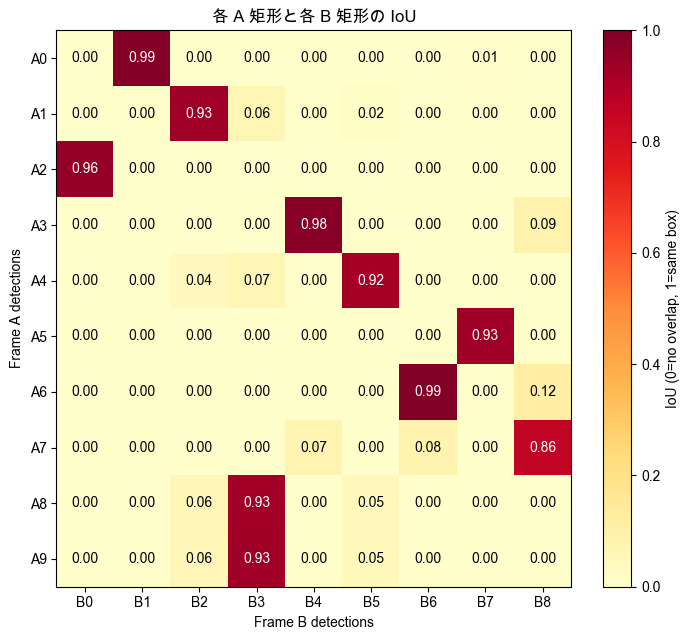

In [6]:
# 色の濃淡で全矩形の関係を表示します。
fig, ax = plt.subplots(figsize=(max(6, len(players_b) * 0.8), max(4, len(players_a) * 0.65)))
heatmap = ax.imshow(matrix, cmap="YlOrRd", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(players_b)), labels=[f"B{j}" for j in range(len(players_b))])
ax.set_yticks(range(len(players_a)), labels=[f"A{i}" for i in range(len(players_a))])
ax.set_xlabel("Frame B detections")
ax.set_ylabel("Frame A detections")
ax.set_title("各 A 矩形と各 B 矩形の IoU")
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        value = matrix[i, j]
        ax.text(j, i, f"{value:.2f}", ha="center", va="center",
                color="white" if value > 0.55 else "black")
fig.colorbar(heatmap, ax=ax, label="IoU (0=no overlap, 1=same box)")
plt.tight_layout()
plt.show()


## Step 4｜各 A 矩形の最良候補を確認する

各行の最大値は、その A 矩形に最もよく重なる B 矩形を示す。ただし最終対応ではない。複数の A 矩形が同じ B 矩形を選ぶ場合があり、次の処理で一対一の制約を適用する。


In [7]:
# 一対一の制約を適用する前に候補を確認します。
best_match_rows = []
for i in range(matrix.shape[0]):
    if matrix.shape[1] == 0:
        break
    j = int(matrix[i].argmax())
    best_match_rows.append({
        "frame_a_box": f"A{i}",
        "best_frame_b_box": f"B{j}",
        "best_iou": float(matrix[i, j]),
        "passes_threshold": bool(matrix[i, j] >= 0.30),
    })

best_match_df = pd.DataFrame(best_match_rows)
best_match_df


,frame_a_box,best_frame_b_box,best_iou,passes_threshold
0,A0,B1,0.986325,True
1,A1,B2,0.931553,True
2,A2,B0,0.955132,True
3,A3,B4,0.978287,True
4,A4,B5,0.921508,True
5,A5,B7,0.933348,True
6,A6,B6,0.990789,True
7,A7,B8,0.857547,True
8,A8,B3,0.928068,True
9,A9,B3,0.933061,True


## Step 5｜全候補を対象に貪欲法で一対一に対応付ける

1. しきい値を超える `(A_i, B_j)` の候補をすべて列挙する。
2. IoU の高い順に並べる。
3. 残りの最高スコアを選ぶ。A または B が使用済みなら、その組を飛ばす。
4. 候補がなくなるまで繰り返す。

これはまだ ByteTrack ではない。ただし行ごとの決定とは異なり、ループで `A0` が先に現れたために、`A1` により適した B 矩形を先取りする問題を避けられる。


In [8]:
# 全候補からスコア順に、競合しない一対一の対応を選びます。
IOU_THRESHOLD = 0.30
candidates = [
    (float(matrix[i, j]), i, j)
    for i in range(matrix.shape[0])
    for j in range(matrix.shape[1])
    if matrix[i, j] >= IOU_THRESHOLD
]
candidates.sort(reverse=True)  # タプルは最初の項目 IoU を優先して並びます。

assignments = []
used_a, used_b = set(), set()
for score, i, j in candidates:
    if i in used_a or j in used_b:
        continue
    used_a.add(i)
    used_b.add(j)
    assignments.append({
        "frame_a_box": f"A{i}",
        "frame_b_box": f"B{j}",
        "iou": round(score, 3),
        "a_index": i,
        "b_index": j,
    })

assignment_df = pd.DataFrame(assignments)
assignment_df[["frame_a_box", "frame_b_box", "iou"]] if not assignment_df.empty else assignment_df


,frame_a_box,frame_b_box,iou
0,A6,B6,0.991
1,A0,B1,0.986
2,A3,B4,0.978
3,A2,B0,0.955
4,A5,B7,0.933
5,A9,B3,0.933
6,A1,B2,0.932
7,A4,B5,0.922
8,A7,B8,0.858


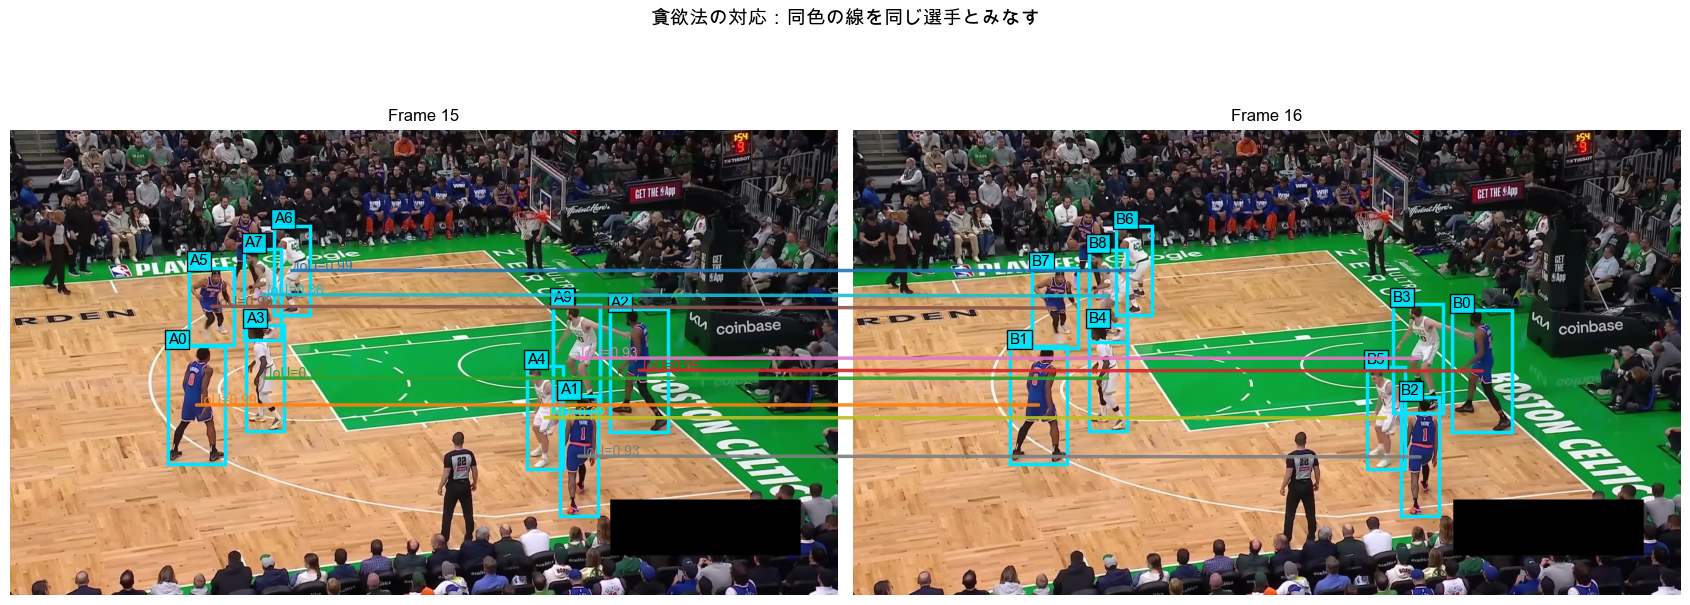

In [9]:
# 対応表の関係を 2 枚の画像に描きます。
fig, axes = plt.subplots(1, 2, figsize=(17, 7))
draw_indexed_boxes(axes[0], frame_a, players_a, "A", f"Frame {FRAME_A}")
draw_indexed_boxes(axes[1], frame_b, players_b, "B", f"Frame {FRAME_B}")

# 型検査で認識できる公開 API からカラーマップを取得します。
colors = plt.get_cmap("tab10")(np.linspace(0, 1, max(1, len(assignments))))
for color, pair in zip(colors, assignments):
    box_a = players_a[pair["a_index"]].bbox_xyxy
    box_b = players_b[pair["b_index"]].bbox_xyxy
    center_a = ((box_a[0] + box_a[2]) / 2, (box_a[1] + box_a[3]) / 2)
    center_b = ((box_b[0] + box_b[2]) / 2, (box_b[1] + box_b[3]) / 2)
    connection = ConnectionPatch(
        xyA=center_b, coordsA=axes[1].transData,
        xyB=center_a, coordsB=axes[0].transData,
        color=color, linewidth=2.5, alpha=0.9,
    )
    fig.add_artist(connection)
    axes[0].text(*center_a, f" IoU={pair['iou']:.2f}", color=color, weight="bold")

fig.suptitle("貪欲法の対応：同色の線を同じ選手とみなす", fontsize=14)
plt.tight_layout()
plt.show()


## 単純な IoU から ByteTrack へ

IoU だけでは、高速移動、交差、遮蔽、見落としに対応しにくい。ByteTrack は追跡状態を保持し、高信頼度・低信頼度の検出を 2 段階で対応付け、一時的に不確かな対象を元の ID に接続する。次の単元では `track_id` と軌跡を観察する。

### 確認問題

1. ヒートマップの同じ行に、近い高スコアが二つあるか。どのような不確かさを表すか。
2. `IOU_THRESHOLD` を `0.10` または `0.60` にすると、対応数はどう変わるか。
3. 正しい組の IoU が低くなるのは、どのようなバスケットボールの場面か。


## 出力

- A／B の番号付きの前後フレーム比較図。
- 全検出組の IoU ヒートマップ。
- 一対一の対応表と、画像間の対応線。

この単元では動画は出力しない。まず 2 フレームの関係を理解し、その後で長い追跡へ進む。
